In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pywt

In [6]:
# Загрузка данных
df = pd.read_csv('data.csv', sep=';', parse_dates=['start_date_time'])

df.set_index('start_date_time', inplace=True)

signal = df['RCORR_E'].values

print(f"Загружено точек: {len(signal)}")
print(f"Период: с {df.index.min()} по {df.index.max()}")

Загружено точек: 8637
Период: с 2024-05-09 00:00:00 по 2024-05-14 23:59:00


In [12]:
import pywt
import numpy as np

# 1. Дополняем сигнал
pad_width = 5760
signal_padded = np.pad(signal, (pad_width, pad_width), mode='symmetric')

# 2. Параметры
Fs = 1 / 60
wavelet_name = 'cmor1.5-1.0'
fc = pywt.central_frequency(wavelet_name)
freqrange = np.array([0.000005, 0.016])

# Переводим частоты в масштабы
scalerange = fc / (freqrange * (1/Fs))

# Формируем масштабы:
scales = np.arange(1, scalerange[0], 1)

print(f"Количество масштабов: {len(scales)}")

# 3. Выполняем НВП.
coeffs, freqs = pywt.cwt(signal_padded, scales, wavelet_name, method='fft')

# 4. Отрезаем краевые эффекты
coeffs_truncated = coeffs[:, pad_width:-pad_width]

print(f"Размер матрицы коэффициентов после обрезки: {coeffs_truncated.shape}")

Количество масштабов: 3333
Размер матрицы коэффициентов после обрезки: (3333, 8637)


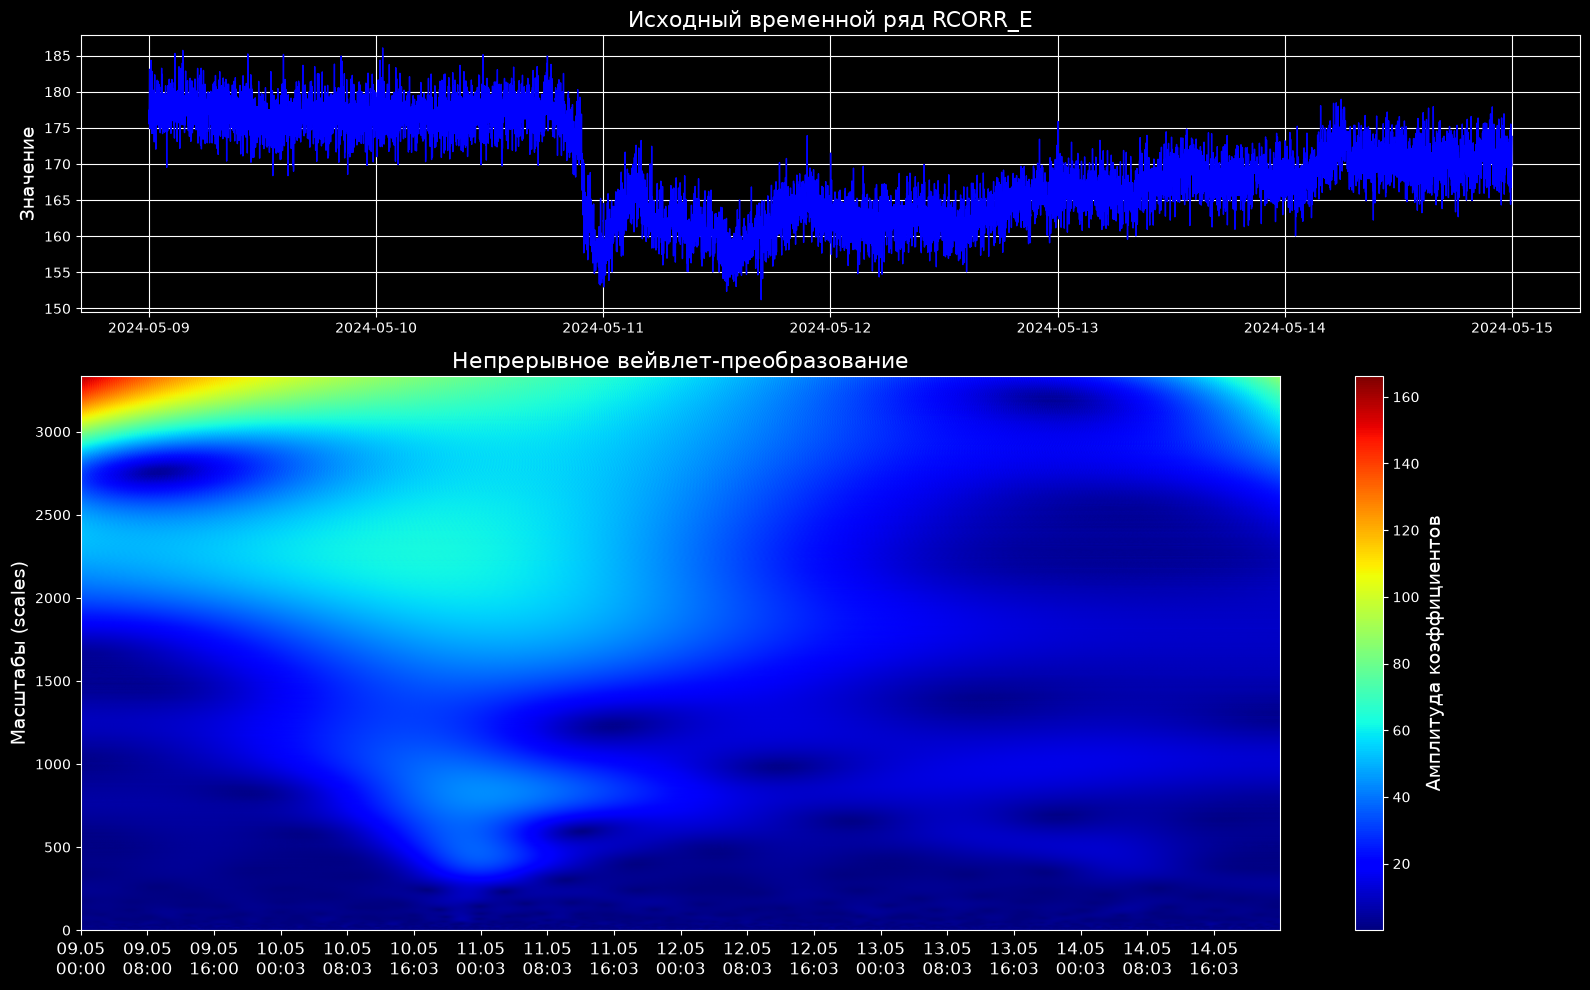

In [16]:

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw={'height_ratios': [1, 2]})

# --- График 1: Исходный временной ряд ---
ax1.plot(df.index, signal, color='blue', linewidth=1)
ax1.set_title('Исходный временной ряд RCORR_E', fontsize=16)
ax1.set_ylabel('Значение', fontsize=14)
ax1.grid(True)

# --- График 2: Вейвлет-спектрограмма (Скалограмма) ---
im = ax2.imshow(np.abs(coeffs_truncated), aspect='auto', cmap='jet', origin='lower')

ax2.set_title('Непрерывное вейвлет-преобразование', fontsize=16)
ax2.set_ylabel('Масштабы (scales)', fontsize=14)

tick_spacing = 480
ticks = np.arange(0, len(signal), tick_spacing)
tick_labels = [df.index[i].strftime('%d.%m\n%H:%M') for i in ticks if i < len(df)]

ax2.set_xticks(ticks)
ax2.set_xticklabels(tick_labels, fontsize=12)

cbar = fig.colorbar(im, ax=ax2)
cbar.set_label('Амплитуда коэффициентов', fontsize=14)

plt.tight_layout()
plt.savefig('plot_1.png', dpi=300, bbox_inches='tight')
plt.show()